# Ford Car Price Prediction
**Goal:** understand what drives used Ford car prices and predict price from car features.

**What changed from the first version (so you can explain it in an interview):**
1. Added a data-quality check (duplicates, impossible years, zero engine sizes) before any analysis.
2. Split train/test **first**, then encode and scale inside a `Pipeline`, so no information from the test set leaks into training.
3. Removed `astype(int)` on the encoded data, which silently chopped decimals off `mpg` and `engineSize`.
4. Compared linear regression with a random forest and added cross-validation, MAE and RMSE.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style='whitegrid')

## 1. Load and first look

In [2]:
df = pd.read_csv('ford.csv')   # on Kaggle use: /kaggle/input/datasets/adhurimquku/ford-car-price-prediction/ford.csv
print(df.shape)
df.head()

(17966, 9)


,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17966 entries, 0 to 17965
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         17966 non-null  str    
 1   year          17966 non-null  int64  
 2   price         17966 non-null  int64  
 3   transmission  17966 non-null  str    
 4   mileage       17966 non-null  int64  
 5   fuelType      17966 non-null  str    
 6   tax           17966 non-null  int64  
 7   mpg           17966 non-null  float64
 8   engineSize    17966 non-null  float64
dtypes: float64(2), int64(4), str(3)
memory usage: 1.6 MB


In [4]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,17966.000000,17966.000000,17966.000000,17966.000000,17966.000000,17966.000000
mean,2016.866470,12279.534844,23362.608761,113.329456,57.906980,1.350807
std,2.050336,4741.343657,19472.054349,62.012456,10.125696,0.432367
min,1996.000000,495.000000,1.000000,0.000000,20.800000,0.000000
25%,2016.000000,8999.000000,9987.000000,30.000000,52.300000,1.000000
50%,2017.000000,11291.000000,18242.500000,145.000000,58.900000,1.200000
75%,2018.000000,15299.000000,31060.000000,145.000000,65.700000,1.500000
max,2060.000000,54995.000000,177644.000000,580.000000,201.800000,5.000000


## 2. Data-quality check (NEW)
A hiring manager wants to see that you look for bad data before modelling.

In [5]:
print('Rows:', len(df))
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Rows with year > 2025 (impossible):', (df['year'] > 2025).sum())
print('Rows with engineSize == 0 (invalid for petrol/diesel):', (df['engineSize'] == 0).sum())
print('Rows with mpg > 100 (check, may be hybrid/electric):', (df['mpg'] > 100).sum())
print('Model names with extra spaces:', (df['model'] != df['model'].str.strip()).sum())
df[df['year'] > 2025]

Rows: 17966
Missing values: 0
Duplicate rows: 154
Rows with year > 2025 (impossible): 1
Rows with engineSize == 0 (invalid for petrol/diesel): 51
Rows with mpg > 100 (check, may be hybrid/electric): 5
Model names with extra spaces: 17965


,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
17726,Fiesta,2060,6495,Automatic,54807,Petrol,205,42.8,1.4


**Decision:** drop exact duplicates, the impossible year, and rows with engine size 0 (about 0.3 percent of the data), and strip the leading space from model names. The `mpg > 100` rows are kept because they could be genuine.

In [6]:
df_clean = df.copy()
df_clean['model'] = df_clean['model'].str.strip()

rows_before = len(df_clean)
df_clean = df_clean.drop_duplicates()
df_clean = df_clean[df_clean['year'] <= 2025]
df_clean = df_clean[df_clean['engineSize'] > 0]
df_clean = df_clean.reset_index(drop=True)

print(f'Rows before: {rows_before}  |  after: {len(df_clean)}  |  removed: {rows_before - len(df_clean)}')

Rows before: 17966  |  after: 17760  |  removed: 206


## 3. Exploratory data analysis

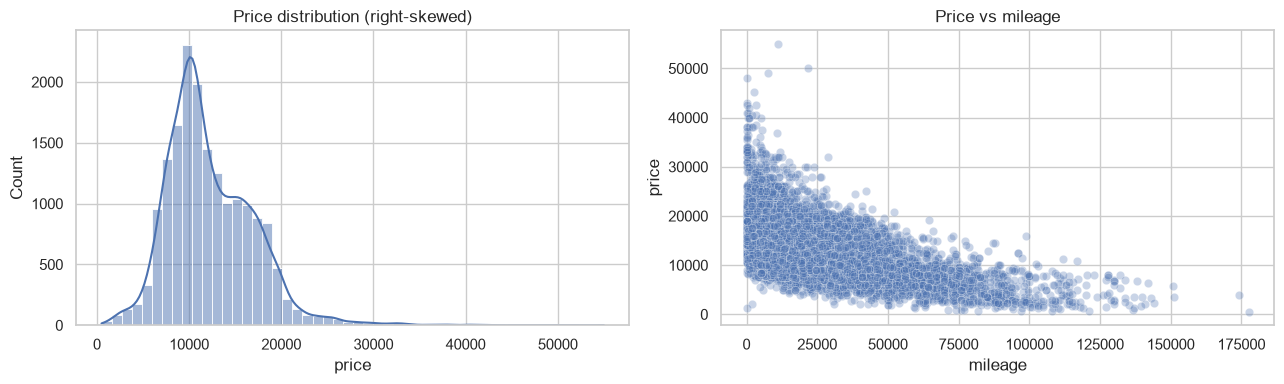

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_clean['price'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Price distribution (right-skewed)')
sns.scatterplot(data=df_clean, x='mileage', y='price', alpha=0.3, ax=axes[1])
axes[1].set_title('Price vs mileage')
plt.tight_layout()

Text(0.5, 1.0, 'Correlation of numeric features')

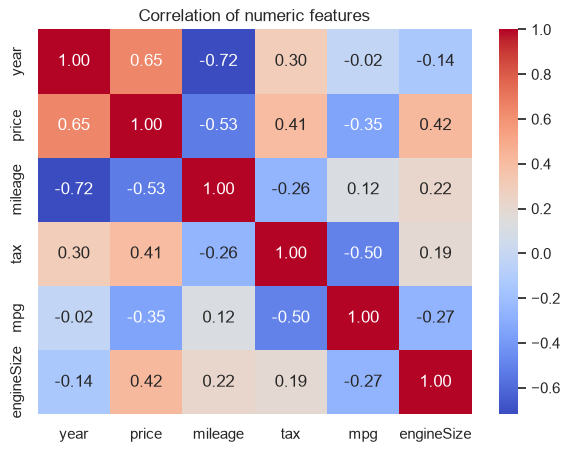

In [8]:
plt.figure(figsize=(7, 5))
sns.heatmap(df_clean.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation of numeric features')

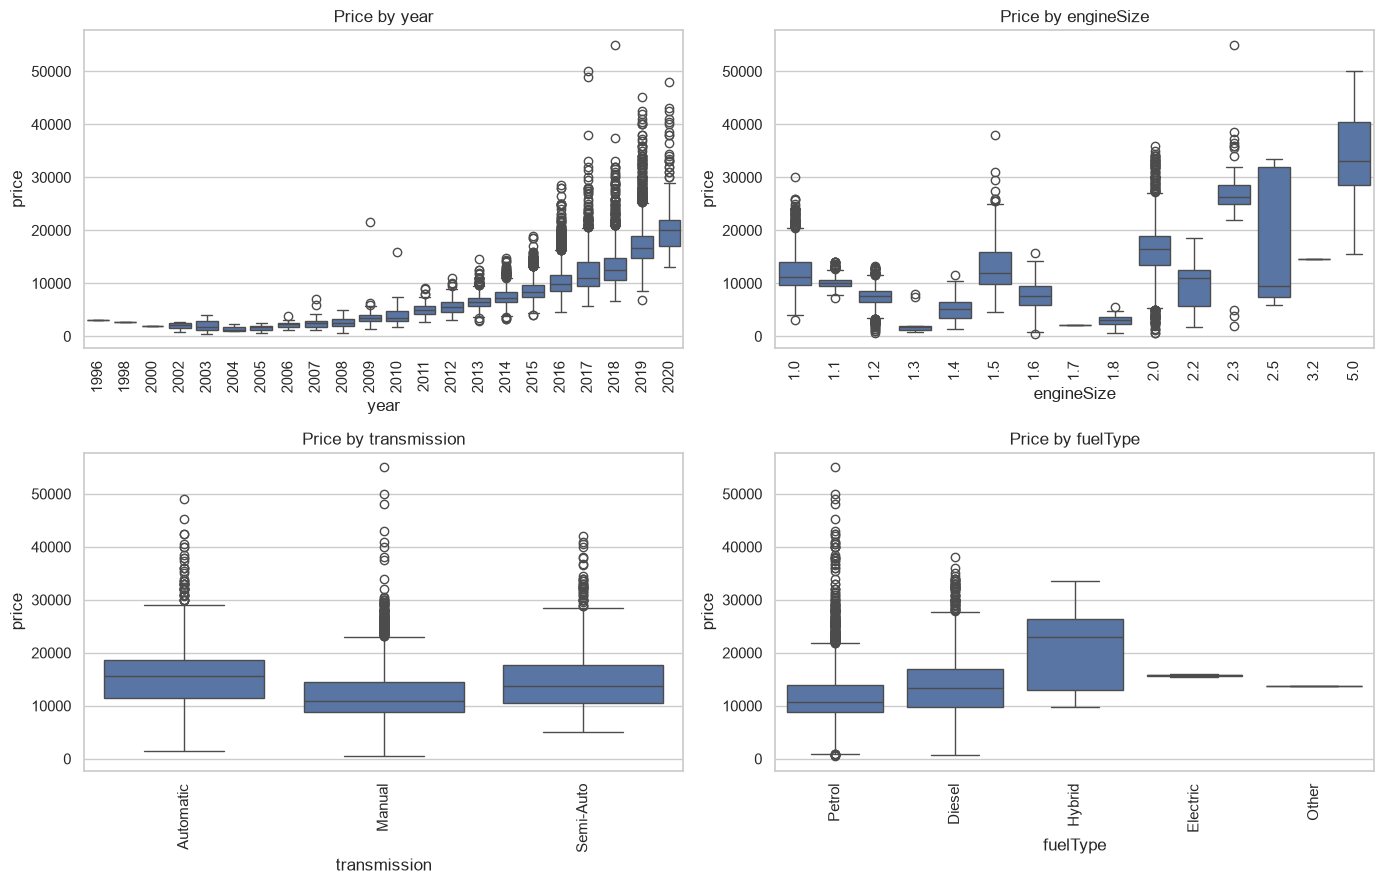

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), ['year', 'engineSize', 'transmission', 'fuelType']):
    sns.boxplot(data=df_clean, x=col, y='price', ax=ax)
    ax.tick_params(axis='x', rotation=90)
    ax.set_title(f'Price by {col}')
plt.tight_layout()

Text(0.5, 1.0, 'Price by model (sorted by median)')

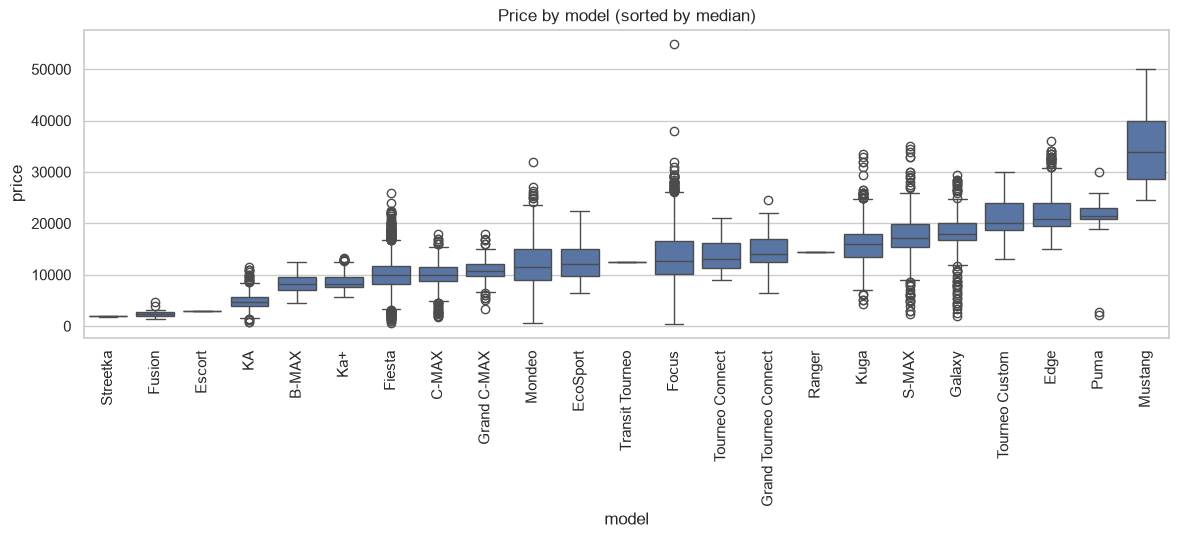

In [10]:
plt.figure(figsize=(14, 4))
order = df_clean.groupby('model')['price'].median().sort_values().index
sns.boxplot(data=df_clean, x='model', y='price', order=order)
plt.xticks(rotation=90)
plt.title('Price by model (sorted by median)')

**Observations to write in your own words:** price is right-skewed; newer cars, bigger engines and automatic transmissions cost more; higher mileage lowers price; the model name matters a lot (Mustang, Puma and Edge have the highest median prices; Streetka, Fusion and Escort the lowest).

## 4. Modelling
**Split first.** Encoding and scaling are learned from the training data only, inside a pipeline.

In [11]:
X = df_clean.drop(columns='price')
y = df_clean['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

cat_cols = ['model', 'transmission', 'fuelType']
num_cols = ['year', 'mileage', 'tax', 'mpg', 'engineSize']

preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

def evaluate(name, pipe):
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    r2 = r2_score(y_test, pred)
    n = X_test.shape[0]
    p = pipe[:-1].transform(X_test).shape[1]
    adj = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    return {'Model': name, 'R2': r2, 'Adj R2': adj,
            'MAE (GBP)': mean_absolute_error(y_test, pred),
            'RMSE (GBP)': np.sqrt(mean_squared_error(y_test, pred))}, pred

In [12]:
lin = Pipeline([('prep', preprocess), ('model', LinearRegression())])
rf = Pipeline([('prep', preprocess), ('model', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))])

lin_res, lin_pred = evaluate('Linear Regression (one-hot)', lin)
rf_res, rf_pred = evaluate('Random Forest (one-hot)', rf)

results = pd.DataFrame([lin_res, rf_res]).round(4)
results

,Model,R2,Adj R2,MAE (GBP),RMSE (GBP)
0,Linear Regression (one-hot),0.8463,0.8453,1356.9431,1895.6429
1,Random Forest (one-hot),0.9230,0.9225,890.7718,1341.5204


### One-hot vs label (ordinal) encoding
The first version of this project compared the two. Here is the same comparison done correctly: ordinal codes make the model think `Mondeo > Focus > Fiesta` in a numeric sense, which has no meaning for a linear model.

In [13]:
preprocess_ord = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols)
])
lin_ord = Pipeline([('prep', preprocess_ord), ('model', LinearRegression())])
lin_ord.fit(X_train, y_train)
r2_ord = r2_score(y_test, lin_ord.predict(X_test))
print(f'Linear Regression with label/ordinal encoding: R2 = {r2_ord:.4f}')

Linear Regression with label/ordinal encoding: R2 = 0.7435


### Cross-validation (more trustworthy than a single split)

In [14]:
cv_lin = cross_val_score(lin, X, y, cv=5, scoring='r2')
cv_rf = cross_val_score(rf, X, y, cv=5, scoring='r2')
print(f'Linear Regression 5-fold R2: {cv_lin.mean():.4f} (+/- {cv_lin.std():.4f})')
print(f'Random Forest    5-fold R2: {cv_rf.mean():.4f} (+/- {cv_rf.std():.4f})')

Linear Regression 5-fold R2: 0.8266 (+/- 0.0353)
Random Forest    5-fold R2: 0.9219 (+/- 0.0040)


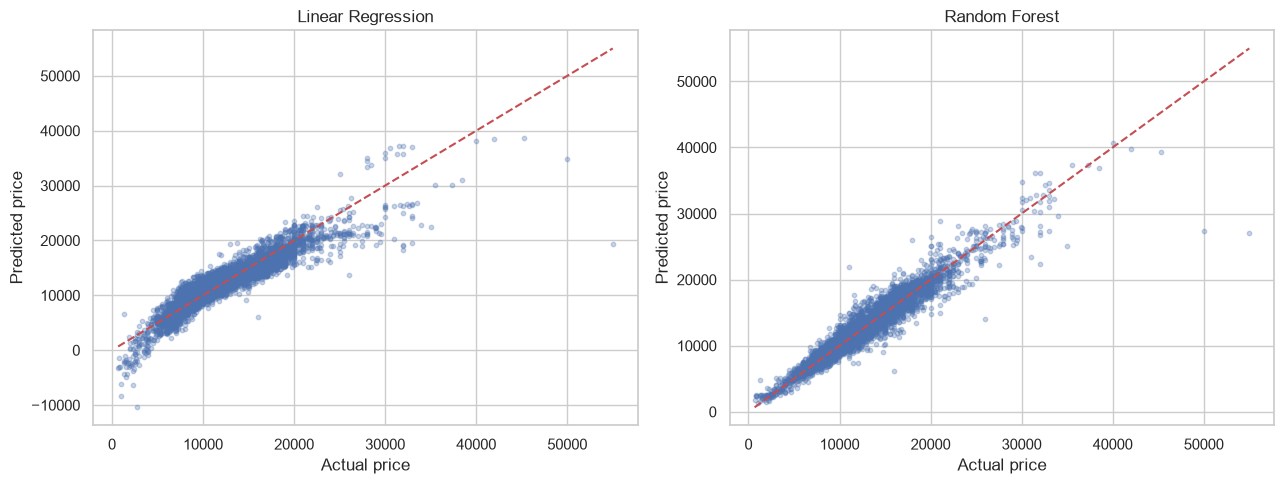

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, pred, title in zip(axes, [lin_pred, rf_pred], ['Linear Regression', 'Random Forest']):
    ax.scatter(y_test, pred, alpha=0.3, s=10)
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, 'r--')
    ax.set_xlabel('Actual price'); ax.set_ylabel('Predicted price'); ax.set_title(title)
plt.tight_layout()

Text(0.5, 1.0, 'Top 10 features (Random Forest)')

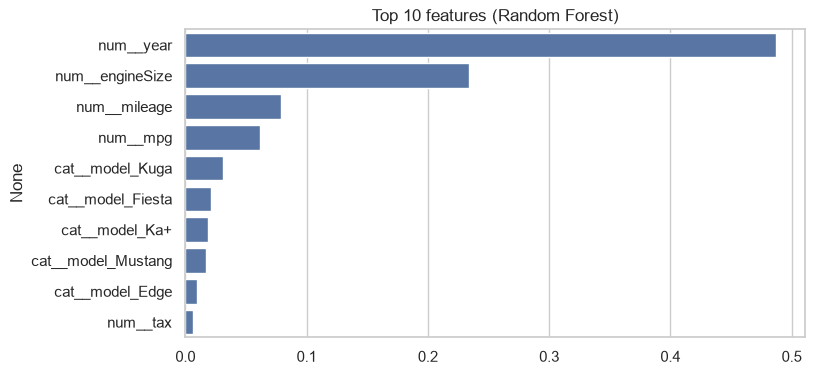

In [16]:
names = rf[:-1].get_feature_names_out()
imp = pd.Series(rf[-1].feature_importances_, index=names).sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 4))
sns.barplot(x=imp.values, y=imp.index)
plt.title('Top 10 features (Random Forest)')

## 5. Findings (generated from the results above)

In [17]:
from IPython.display import Markdown
top = ', '.join(imp.index[:3])
Markdown(f'''
- Cleaned **{rows_before:,} to {len(df_clean):,}** rows by removing duplicates and impossible values (year 2060, engine size 0).
- Linear regression reached **R2 = {lin_res['R2']:.2f}** (average error about GBP {lin_res['MAE (GBP)']:,.0f}).
- A random forest improved this to **R2 = {rf_res['R2']:.2f}** (average error about GBP {rf_res['MAE (GBP)']:,.0f}), so price has non-linear patterns.
- One-hot encoding (R2 {lin_res['R2']:.2f}) beat label encoding (R2 {r2_ord:.2f}) for a linear model.
- Most important features for the random forest: **{top}**.
- 5-fold cross-validation gave similar scores, so results are not a lucky split.
''')


- Cleaned **17,966 to 17,760** rows by removing duplicates and impossible values (year 2060, engine size 0).
- Linear regression reached **R2 = 0.85** (average error about GBP 1,357).
- A random forest improved this to **R2 = 0.92** (average error about GBP 891), so price has non-linear patterns.
- One-hot encoding (R2 0.85) beat label encoding (R2 0.74) for a linear model.
- Most important features for the random forest: **num__year, num__engineSize, num__mileage**.
- 5-fold cross-validation gave similar scores, so results are not a lucky split.
